# limen — priming analysis

Loads `data/priming.json`, produces a tidy table, and renders descriptive plots.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

from limen.analysis import load_trials, summarize, save_summary

DATA = Path("../data/priming.json")
SUMMARY = Path("../data/priming_summary.json")

In [2]:
df = load_trials(DATA)
df

,pair_id,condition,prime,target,target_novelty,target_similarity,target_best_match,top_source,top_salience
0,0,related,doctor,nurse,1.0,0.0,None,memory,0.6
1,0,unrelated,bread,nurse,1.0,0.0,None,memory,0.6
2,1,related,bread,butter,1.0,0.0,None,memory,0.6
3,1,unrelated,cat,butter,1.0,0.0,None,memory,0.6
4,2,related,cat,dog,1.0,0.0,None,memory,0.6
5,2,unrelated,rain,dog,1.0,0.0,None,memory,0.6
6,3,related,rain,umbrella,1.0,0.0,None,memory,0.6
7,3,unrelated,car,umbrella,1.0,0.0,None,memory,0.6
8,4,related,car,road,1.0,0.0,None,memory,0.6
9,4,unrelated,doctor,road,1.0,0.0,None,memory,0.6


In [3]:
summary = summarize(df)
summary

{'related': {'n': 5,
  'target_novelty_mean': 1.0,
  'target_novelty_std': 0.0,
  'target_similarity_mean': 0.0,
  'target_similarity_std': 0.0,
  'top_salience_mean': 0.6000000000000001,
  'top_salience_std': 0.0,
  'top_source_counts': {'memory': 5}},
 'unrelated': {'n': 5,
  'target_novelty_mean': 1.0,
  'target_novelty_std': 0.0,
  'target_similarity_mean': 0.0,
  'target_similarity_std': 0.0,
  'top_salience_mean': 0.6000000000000001,
  'top_salience_std': 0.0,
  'top_source_counts': {'memory': 5}}}

In [4]:
save_summary(summary, SUMMARY)
print(f"wrote {SUMMARY}")

wrote ../data/priming_summary.json


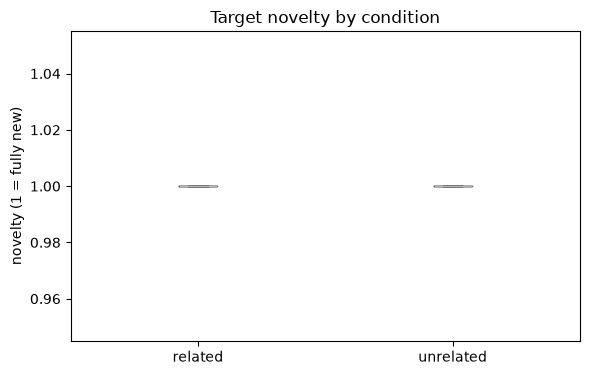

In [5]:
# Novelty by condition
fig, ax = plt.subplots(figsize=(6, 4))
df.boxplot(column="target_novelty", by="condition", ax=ax, grid=False)
ax.set_title("Target novelty by condition")
ax.set_ylabel("novelty (1 = fully new)")
ax.set_xlabel("")
plt.suptitle("")
plt.tight_layout()
plt.show()

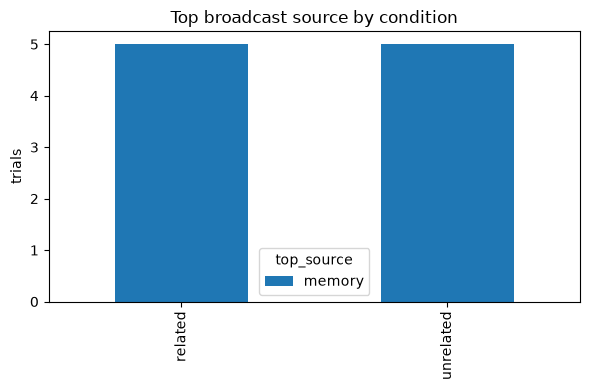

In [6]:
# Top broadcast source by condition
counts = df.groupby(["condition", "top_source"]).size().unstack(fill_value=0)
counts.plot(kind="bar", stacked=True, figsize=(6, 4))
plt.title("Top broadcast source by condition")
plt.ylabel("trials")
plt.xlabel("")
plt.tight_layout()
plt.show()

In [8]:
# Raw trial rows
df.sort_values(["condition", "pair_id"])

,pair_id,condition,prime,target,target_novelty,target_similarity,target_best_match,top_source,top_salience
0,0,related,doctor,nurse,1.0,0.0,None,memory,0.6
2,1,related,bread,butter,1.0,0.0,None,memory,0.6
4,2,related,cat,dog,1.0,0.0,None,memory,0.6
6,3,related,rain,umbrella,1.0,0.0,None,memory,0.6
8,4,related,car,road,1.0,0.0,None,memory,0.6
1,0,unrelated,bread,nurse,1.0,0.0,None,memory,0.6
3,1,unrelated,cat,butter,1.0,0.0,None,memory,0.6
5,2,unrelated,rain,dog,1.0,0.0,None,memory,0.6
7,3,unrelated,car,umbrella,1.0,0.0,None,memory,0.6
9,4,unrelated,doctor,road,1.0,0.0,None,memory,0.6
